In [2]:
"""
Diachronic Projections for Passio/Pathos
ERC Proposal Case Study: Visualizing Sense Lineages
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import umap
import tempun
from pathlib import Path

# Import our helpers
from projections_helpers import REDUCTIONS, get_2d, evaluate_projection_2d, create_label_palette
from lda_projections import LDAProjection, compute_lda_projection, evaluate_lda_vs_unsupervised

2026-07-03 11:28:26.753682: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-03 11:28:26.794074: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
# Load classified datasets
passio_df = (pd.read_parquet("../data/large_files/passio_sample1000_classified.parquet"))
pathos_df = pd.read_parquet("../data/large_files/pathos_sample1000_classified.parquet")

print(f"Passio: {len(passio_df)} instances")
print(f"Pathos: {len(pathos_df)} instances")

Passio: 1000 instances
Pathos: 1000 instances


In [4]:


# Add temporal data
def get_random_date(row):
    random_date = tempun.model_date(row["not_before"], row["not_after"])
    if isinstance(random_date, (list, tuple)):
        random_date = random_date[0]
    return random_date

passio_df["random_date"] = passio_df.apply(get_random_date, axis=1)
pathos_df["random_date"] = pathos_df.apply(get_random_date, axis=1)

In [5]:
passio_df = passio_df[passio_df["random_date"].notna()]
pathos_df = pathos_df[pathos_df["random_date"].notna()]

In [6]:
passio_df = passio_df[passio_df["class_llama3.3"].notna()]
pathos_df = pathos_df[pathos_df["class_llama3.3"].notna()]

In [7]:
# Extract embeddings (PhilBerta layer 11)
X_passio = np.stack(passio_df["emb_philberta_l11"])
y_passio = passio_df["class_llama3.3"].astype(int).values

X_pathos = np.stack(pathos_df["emb_philberta_l11"])
y_pathos = pathos_df["class_llama3.3"].astype(int).values

In [8]:
print(f"Passio: {len(passio_df)} instances")
print(f"Pathos: {len(pathos_df)} instances")

Passio: 914 instances
Pathos: 999 instances


In [9]:
# =============================================================================
# IMPROVED: Compare LDA vs Stronger Baselines (including pca10_tsne)
# =============================================================================
print('=== COMPREHENSIVE COMPARISON: Passio AND Pathos ===\n')

def compare_all_methods(X, y, name):
    print(f'--- {name} ---')
    
    # Compute LDA
    X_lda, lda = compute_lda_projection(X, y)
    sil_lda = silhouette_score(X_lda, y)
    
    # Compute PCA
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X)
    sil_pca = silhouette_score(X_pca, y)
    
    # Compute pca10_tsne (stronger baseline)
    from sklearn.manifold import TSNE
    pca_10 = PCA(n_components=10, random_state=42)
    X_pca10 = pca_10.fit_transform(X)
    tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=42)
    X_pca10_tsne = tsne.fit_transform(X_pca10)
    sil_pca10_tsne = silhouette_score(X_pca10_tsne, y)
    
    # Compute UMAP variants
    umap_50 = umap.UMAP(n_neighbors=50, min_dist=0.5, metric='cosine', random_state=42)
    X_umap = umap_50.fit_transform(X)
    sil_umap = silhouette_score(X_umap, y)
    
    results = {
        'PCA': sil_pca,
        'PCA+TSNE(10)': sil_pca10_tsne,
        'UMAP(50,0.5)': sil_umap,
        'LDA (supervised)': sil_lda
    }
    
    for method, score in sorted(results.items(), key=lambda x: x[1], reverse=True):
        print(f'{method:20s}: {score:.4f}')
    
    return results, lda, X_lda, X_pca, X_pca10_tsne, X_umap

# Run for both datasets
results_passio, lda_passio, X_lda_passio, X_pca_passio, X_pca10tsne_passio, X_umap_passio = compare_all_methods(X_passio, y_passio, 'PASSIO')
print()
results_pathos, lda_pathos, X_lda_pathos, X_pca_pathos, X_pca10tsne_pathos, X_umap_pathos = compare_all_methods(X_pathos, y_pathos, 'PATHOS')

=== COMPREHENSIVE COMPARISON: Passio AND Pathos ===

--- PASSIO ---


/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


LDA (supervised)    : 0.3622
UMAP(50,0.5)        : -0.0899
PCA+TSNE(10)        : -0.1197
PCA                 : -0.1730

--- PATHOS ---


/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


LDA (supervised)    : 0.5358
UMAP(50,0.5)        : -0.0729
PCA                 : -0.0759
PCA+TSNE(10)        : -0.1011


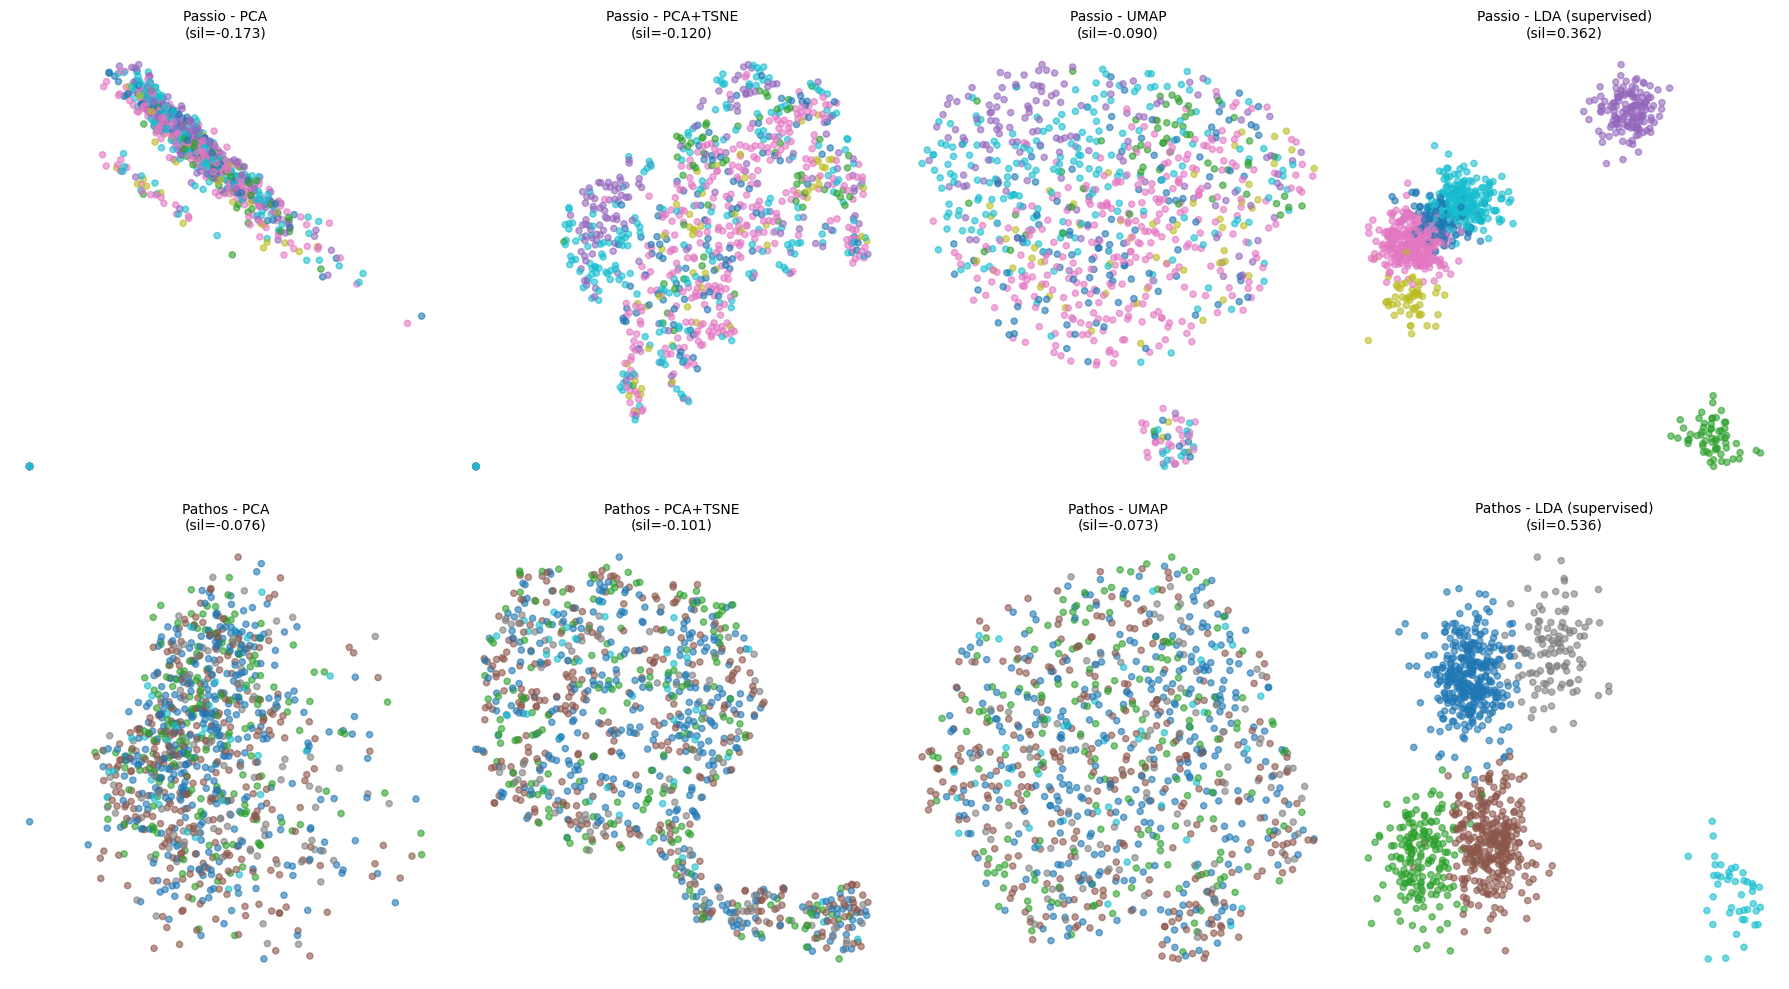


Key observation: LDA achieves clear separation while unsupervised methods show overlapping clusters.

=== Top 5 Discriminative Dimensions ===

PASSIO:
  Dim 723: 194.693
  Dim 182: 55.974
  Dim 664: 30.758
  Dim 686: 22.023
  Dim 580: 19.956

PATHOS:
  Dim 723: 29.333
  Dim 277: 11.033
  Dim 389: 9.937
  Dim 575: 9.267
  Dim 423: 8.904


In [10]:
# =============================================================================
# VISUALIZATION: Side-by-side comparison for Passio AND Pathos
# =============================================================================
fig, axes = plt.subplots(2, 4, figsize=(18, 10))

cmap = 'tab10'

# PASSIO ROW
axes[0, 0].scatter(X_pca_passio[:, 0], X_pca_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 0].set_title(f'Passio - PCA\n(sil={results_passio["PCA"]:.3f})', fontsize=10)
axes[0, 0].axis('off')

axes[0, 1].scatter(X_pca10tsne_passio[:, 0], X_pca10tsne_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 1].set_title(f'Passio - PCA+TSNE\n(sil={results_passio["PCA+TSNE(10)"]:.3f})', fontsize=10)
axes[0, 1].axis('off')

axes[0, 2].scatter(X_umap_passio[:, 0], X_umap_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 2].set_title(f'Passio - UMAP\n(sil={results_passio["UMAP(50,0.5)"]:.3f})', fontsize=10)
axes[0, 2].axis('off')

axes[0, 3].scatter(X_lda_passio[:, 0], X_lda_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 3].set_title(f'Passio - LDA (supervised)\n(sil={results_passio["LDA (supervised)"]:.3f})', fontsize=10)
axes[0, 3].axis('off')

# PATHOS ROW
axes[1, 0].scatter(X_pca_pathos[:, 0], X_pca_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 0].set_title(f'Pathos - PCA\n(sil={results_pathos["PCA"]:.3f})', fontsize=10)
axes[1, 0].axis('off')

axes[1, 1].scatter(X_pca10tsne_pathos[:, 0], X_pca10tsne_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 1].set_title(f'Pathos - PCA+TSNE\n(sil={results_pathos["PCA+TSNE(10)"]:.3f})', fontsize=10)
axes[1, 1].axis('off')

axes[1, 2].scatter(X_umap_pathos[:, 0], X_umap_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 2].set_title(f'Pathos - UMAP\n(sil={results_pathos["UMAP(50,0.5)"]:.3f})', fontsize=10)
axes[1, 2].axis('off')

axes[1, 3].scatter(X_lda_pathos[:, 0], X_lda_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 3].set_title(f'Pathos - LDA (supervised)\n(sil={results_pathos["LDA (supervised)"]:.3f})', fontsize=10)
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

print('\nKey observation: LDA achieves clear separation while unsupervised methods show overlapping clusters.')

# Feature importance
print('\n=== Top 5 Discriminative Dimensions ===')
print('\nPASSIO:')
top_dims_passio = lda_passio.get_top_dimensions(k=5)
importances_passio = lda_passio.get_feature_importances()
for idx in top_dims_passio:
    print(f'  Dim {idx:3d}: {importances_passio[idx]:.3f}')

print('\nPATHOS:')
top_dims_pathos = lda_pathos.get_top_dimensions(k=5)
importances_pathos = lda_pathos.get_feature_importances()
for idx in top_dims_pathos:
    print(f'  Dim {idx:3d}: {importances_pathos[idx]:.3f}')

In [11]:
from projections_helpers import (
         compute_century_trajectories_data,
         plot_3d_century_trajectories,
         create_label_palette
     )

In [12]:
# Prepare label names for plotting - use actual sense names from LABEL_MAP

from llmprompt_passio import LABEL_MAP as LABEL_MAP_PASSIO
from llmprompt_pathos import LABEL_MAP as LABEL_MAP_PATHOS



label_names_passio = LABEL_MAP_PASSIO
label_names_pathos = LABEL_MAP_PATHOS

# Create color palettes - must match number of unique labels in data
palette_passio = create_label_palette(len(np.unique(y_passio)))
palette_pathos = create_label_palette(len(np.unique(y_pathos)))

In [13]:
from importlib import reload
import projections_helpers
reload(projections_helpers)
from projections_helpers import (
         compute_century_trajectories_data,
         plot_3d_century_trajectories,
         create_label_palette,
        plot_3d_lda_temporal
     )   #%%



In [14]:
trajectories_passio = compute_century_trajectories_data(
         df=passio_df,
         X=X_passio,
         y=y_passio,
         lda_model=lda_passio,
         date_column='random_date',
         min_samples=5
     )     #%%

In [15]:
trajectories_passio

{0: {'centuries': [150,
   250,
   350,
   450,
   550,
   650,
   750,
   850,
   1050,
   1150,
   1250,
   1550,
   1750],
  'x': [-3.9223484992980957,
   -1.8120478391647339,
   -2.1036105155944824,
   -2.517913341522217,
   -2.5869884490966797,
   -2.1789629459381104,
   -2.567706823348999,
   -2.5381762981414795,
   -2.7210726737976074,
   -2.3604001998901367,
   -2.3162355422973633,
   -1.9643176794052124,
   -3.7851500511169434],
  'y': [0.6364952921867371,
   0.15326231718063354,
   0.09612876176834106,
   -0.2471209168434143,
   0.7589150667190552,
   -0.37116432189941406,
   0.4379311800003052,
   -0.023230791091918945,
   0.6512756943702698,
   0.4526861906051636,
   0.49496734142303467,
   -0.14537155628204346,
   2.012206554412842],
  'z': [150, 250, 350, 450, 550, 650, 750, 850, 1050, 1150, 1250, 1550, 1750],
  'marker_sizes': [50.0,
   80.10299956639813,
   180.10299956639813,
   134.50980400142566,
   140.30899869919435,
   80.10299956639813,
   140.30899869919435,
   

In [16]:
trajectories_pathos = compute_century_trajectories_data(
         df=pathos_df,
         X=X_pathos,
         y=y_pathos,
         lda_model=lda_pathos,
         date_column='random_date',
         min_samples=5
     )     #%%

In [17]:
trajectories_pathos

{0: {'centuries': [-550,
   -450,
   -350,
   -250,
   -150,
   -50,
   50,
   150,
   250,
   350,
   450,
   550,
   650,
   750,
   850,
   950,
   1050,
   1150,
   1350],
  'x': [1.1385327577590942,
   0.4379293918609619,
   -0.6905690431594849,
   -1.4650524854660034,
   -0.40004199743270874,
   -0.6545805931091309,
   -0.6859228014945984,
   -1.0914363861083984,
   -1.0744718313217163,
   -0.9221831560134888,
   -0.5817775130271912,
   -0.9792501330375671,
   -0.8519474267959595,
   -1.6106321811676025,
   -0.6814568042755127,
   -1.0428597927093506,
   -0.8225889205932617,
   -0.981623649597168,
   -0.7092512845993042],
  'y': [3.6026699542999268,
   2.764657974243164,
   2.6378238201141357,
   2.461915969848633,
   3.1905338764190674,
   3.1127047538757324,
   2.8574838638305664,
   2.5504884719848633,
   2.9075653553009033,
   2.46575665473938,
   2.6264119148254395,
   2.554011583328247,
   3.381286859512329,
   4.1529364585876465,
   2.9980430603027344,
   2.341788291931152

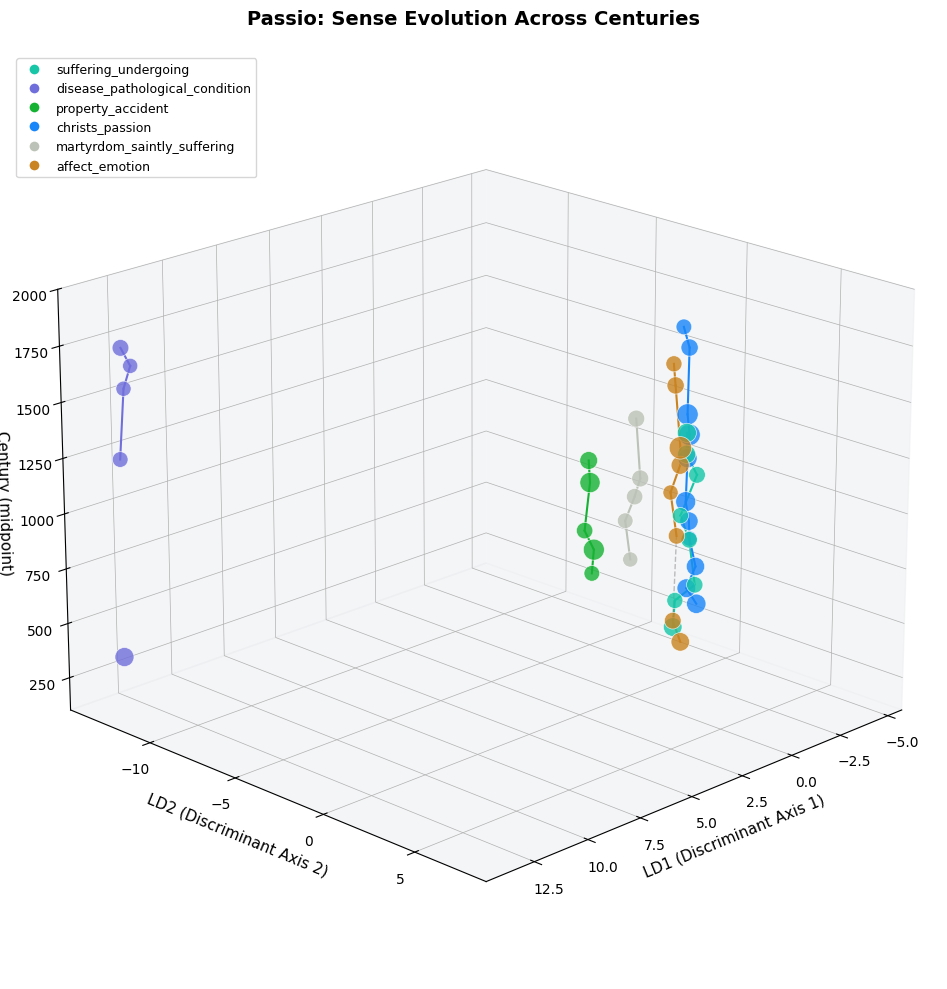

In [18]:
# Create palette and plot
palette_passio = create_label_palette(len(LABEL_MAP_PASSIO))
fig_passio = plot_3d_century_trajectories(
         trajectory_data=trajectories_passio,
         label_names=LABEL_MAP_PASSIO,
         palette=palette_passio,
         title="Passio: Sense Evolution Across Centuries",
         figsize=(14, 10),
         interpolate_gaps=True,
         max_gap_centuries=2
     )
plt.show()

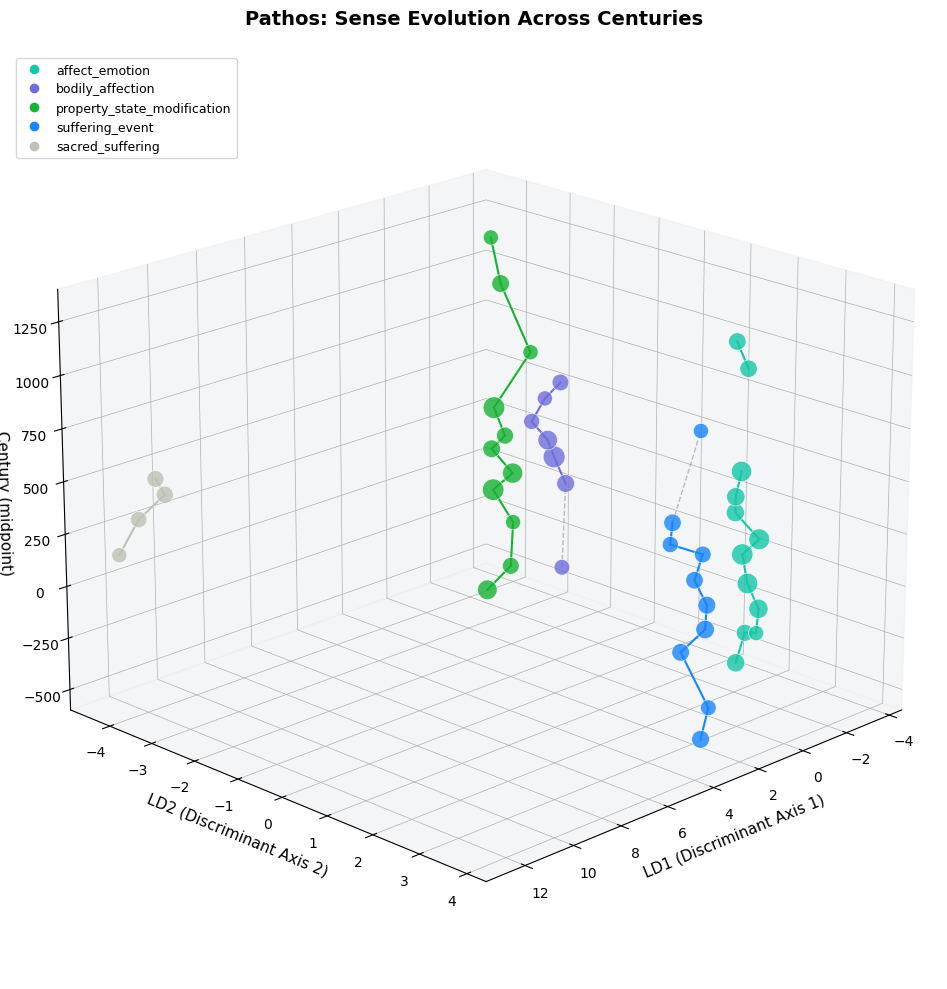

In [19]:
palette_pathos = create_label_palette(len(LABEL_MAP_PATHOS))
fig_pathos = plot_3d_century_trajectories(
         trajectory_data=trajectories_pathos,
         label_names=LABEL_MAP_PATHOS,
         palette=palette_pathos,
         title="Pathos: Sense Evolution Across Centuries",
         figsize=(14, 10),
         interpolate_gaps=True,
         max_gap_centuries=2
     )
plt.show()

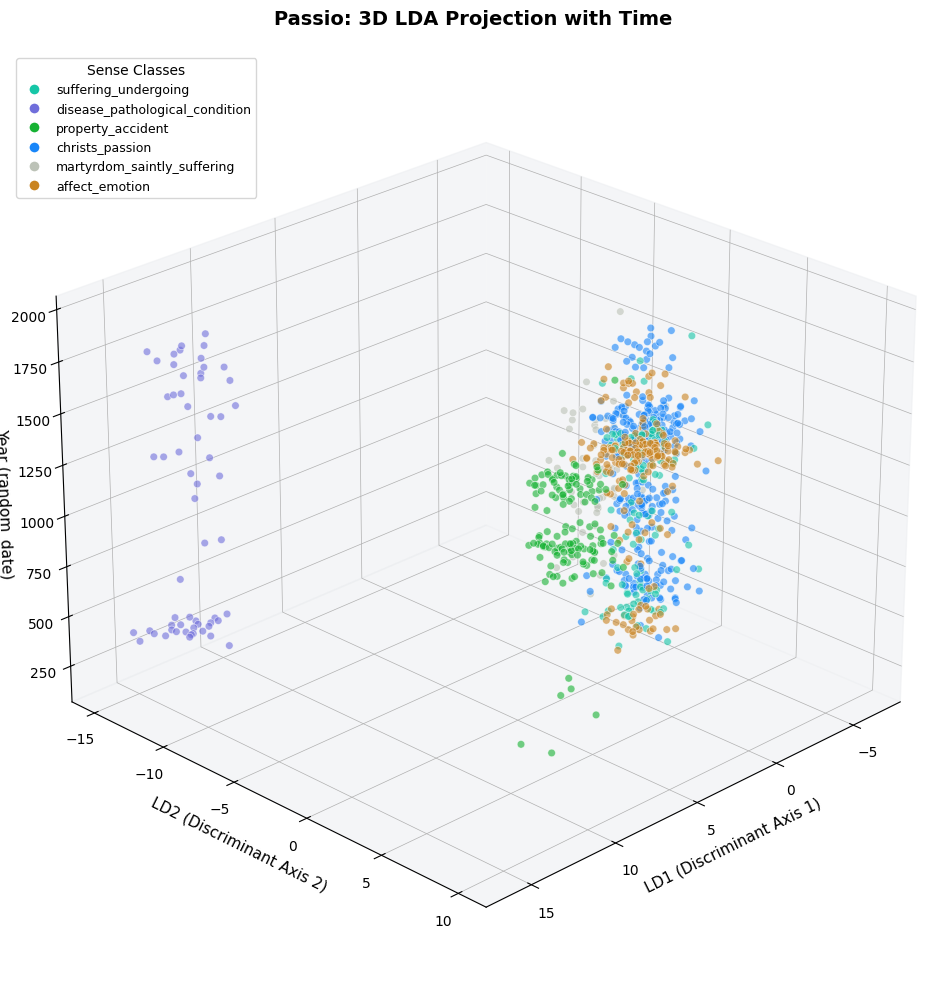

In [20]:
# For Passio
fig_passio, ax_passio = plot_3d_lda_temporal(
    X_lda=X_lda_passio,           # 2D LDA projection (shape: n_samples x 2)
    dates=passio_df["random_date"].values[:len(X_lda_passio)],  # Aligned dates
    labels=y_passio,              # Sense labels (must match X_lda length)
    label_names=LABEL_MAP_PASSIO, # Now uses actual sense names ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
    palette=palette_passio,       # Color palette from create_label_palette()
    title="Passio: 3D LDA Projection with Time",
    figsize=(14, 10)
)

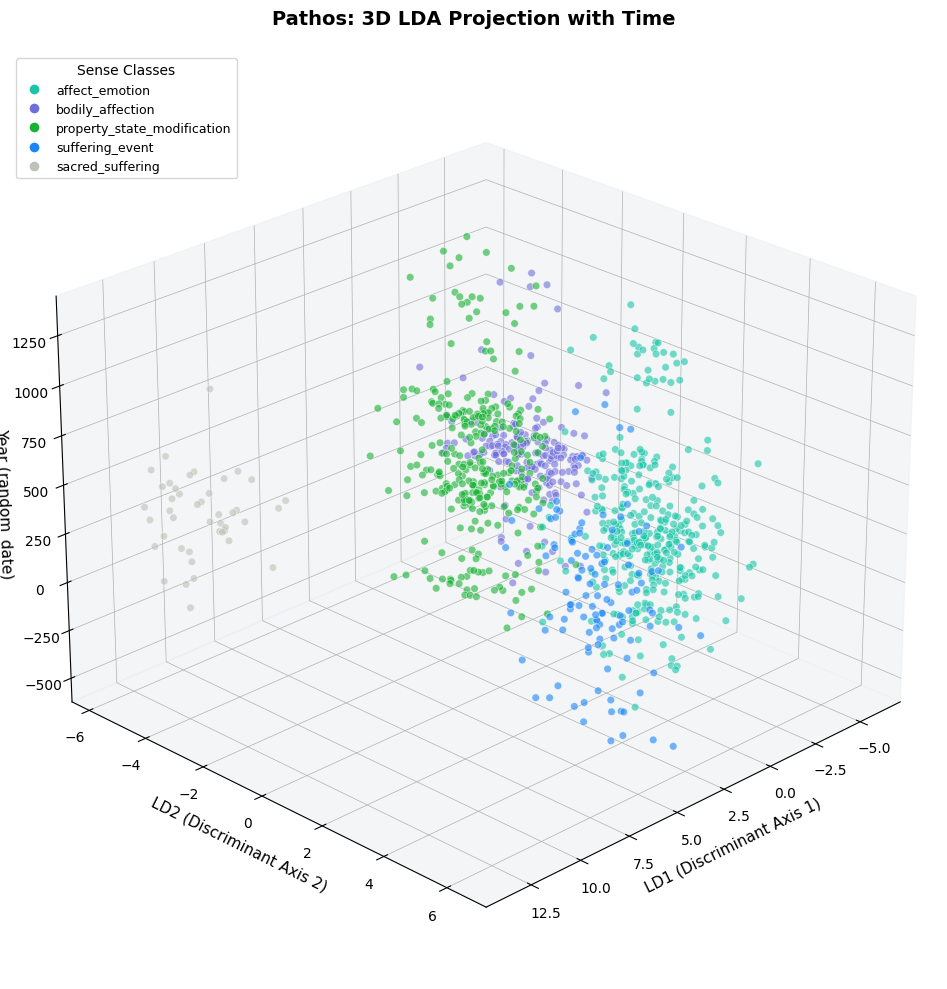

In [21]:
# For Passio
fig_pathos, ax_pathos = plot_3d_lda_temporal(
    X_lda=X_lda_pathos,           # 2D LDA projection (shape: n_samples x 2)
    dates=pathos_df["random_date"].values[:len(X_lda_pathos)],  # Aligned dates
    labels=y_pathos,              # Sense labels (must match X_lda length)
    label_names=LABEL_MAP_PATHOS, # Now uses actual sense names ﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿﷿
    palette=palette_pathos,       # Color palette from create_label_palette()
    title="Pathos: 3D LDA Projection with Time",
    figsize=(14, 10)
)